# 05 — Perguntas de negócio 1 a 6

Esta análise responde às perguntas de negócio do README usando o CSV bruto e a limpeza já implementada em `src.data`. As funções `load_raw`, `rename_columns`, `convert_types`, `remove_invalid`, `drop_duplicates` e `clean` são reutilizadas. `build_features` de `src.features` calcula `waiting_days`, `weekday` e `same_day`.

A P5 reutiliza `add_patient_history` de `src.features`, a mesma implementação compartilhada do `main`, adaptando apenas a definição dos grupos de histórico.

As tabelas agregadas são salvas em `reports/tabelas_perguntas_negocio.csv` e os gráficos em `reports/figures/`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_raw, rename_columns, convert_types, remove_invalid, drop_duplicates, clean
from src.features import build_features, add_patient_history

RAW_PATH = ROOT / "data" / "raw" / "KaggleV2-May-2016.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_PATH = ROOT / "reports" / "tabelas_perguntas_negocio.csv"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


In [2]:
raw_original = load_raw(RAW_PATH)
raw = convert_types(rename_columns(raw_original))
invalid = remove_invalid(raw)
clean_base = drop_duplicates(invalid).reset_index(drop=True)
df = build_features(clean_base)

cleaning_summary = pd.DataFrame({
    "etapa": ["CSV bruto", "Após remover idade < 0 ou espera < 0", "Após deduplicação"],
    "linhas": [len(raw), len(invalid), len(df)],
    "removidas_na_etapa": [0, len(raw) - len(invalid), len(invalid) - len(df)]
})
display(cleaning_summary)
print(f"Idades acima de 100 mantidas: {(raw['age'] > 100).sum()}")
print(f"Duplicatas ignorando AppointmentID e No-show (informativas): {len(raw) - len(raw.drop_duplicates(subset=[c for c in raw.columns if c not in {'appointment_id', 'no_show'}]))}")

,etapa,linhas,removidas_na_etapa
0,CSV bruto,110527,0
1,Após remover idade < 0 ou espera < 0,110521,6
2,Após deduplicação,109889,632


Idades acima de 100 mantidas: 7
Duplicatas ignorando AppointmentID e No-show (informativas): 632


## Limpeza aplicada

A limpeza removida foi exatamente a da pipeline existente: conversão de tipos, remoção de idade negativa e espera negativa, seguida da deduplicação definida em `src.data`. Idades acima de 100 não são removidas. A deduplicação não é refeita manualmente no notebook.

In [3]:
GENERAL_RATE = df["no_show"].mean()
all_tables = []
def rate_table(data, group_col, question, order=None, label_col=None):
    out = data.groupby(group_col, observed=False)["no_show"].agg(n="size", faltas="sum").reset_index()
    out["taxa_falta_%"] = 100 * out["faltas"] / out["n"]
    if order is not None:
        out[group_col] = pd.Categorical(out[group_col], categories=order, ordered=True)
        out = out.sort_values(group_col)
    if label_col and label_col != group_col:
        out = out.rename(columns={group_col: label_col})
    out.insert(0, "pergunta", question)
    all_tables.append(out.copy())
    return out

def add_general_line(ax):
    ax.axhline(100 * GENERAL_RATE, color="black", linestyle=":", linewidth=1.5, label=f"Taxa geral: {100*GENERAL_RATE:.2f}%")
    ax.legend()

def show_table(table):
    display(table.style.format({"taxa_falta_%": "{:.2f}"}))

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()


## P1 — Taxa geral, faixa etária, sexo e bairro

Bairros são filtrados para `n >= 500`; a tabela traz os 10 maiores e os 10 menores entre os elegíveis.

Taxa geral de faltas: 20.103013% (n=109889)
Bairros fora por n < 500: 27


,pergunta,faixa_etaria,n,faltas,taxa_falta_%
0,P1,0-12,20952,4277,20.41
1,P1,13-17,6303,1679,26.64
2,P1,18-29,16621,4088,24.60
3,P1,30-44,21852,4738,21.68
4,P1,45-59,23085,4103,17.77
5,P1,60+,21076,3206,15.21


,pergunta,gender,n,faltas,taxa_falta_%
0,P1,F,71409,14449,20.23
1,P1,M,38480,7642,19.86


,pergunta,recorte_bairro,neighbourhood,n,faltas,taxa_falta_%
70,P1,10 maiores,SANTOS DUMONT,1274,368,28.89
62,P1,10 maiores,SANTA CLARA,501,132,26.35
36,P1,10 maiores,ITARARÉ,3469,902,26.00
40,P1,10 maiores,JESUS DE NAZARETH,2852,695,24.37
33,P1,10 maiores,ILHA DO PRÍNCIPE,2266,532,23.48
9,P1,10 maiores,CARATOÍRA,2540,582,22.91
56,P1,10 maiores,PRAIA DO SUÁ,1288,294,22.83
1,P1,10 maiores,ANDORINHAS,2191,495,22.59
27,P1,10 maiores,GURIGICA,2014,454,22.54
52,P1,10 maiores,PARQUE MOSCOSO,797,179,22.46


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


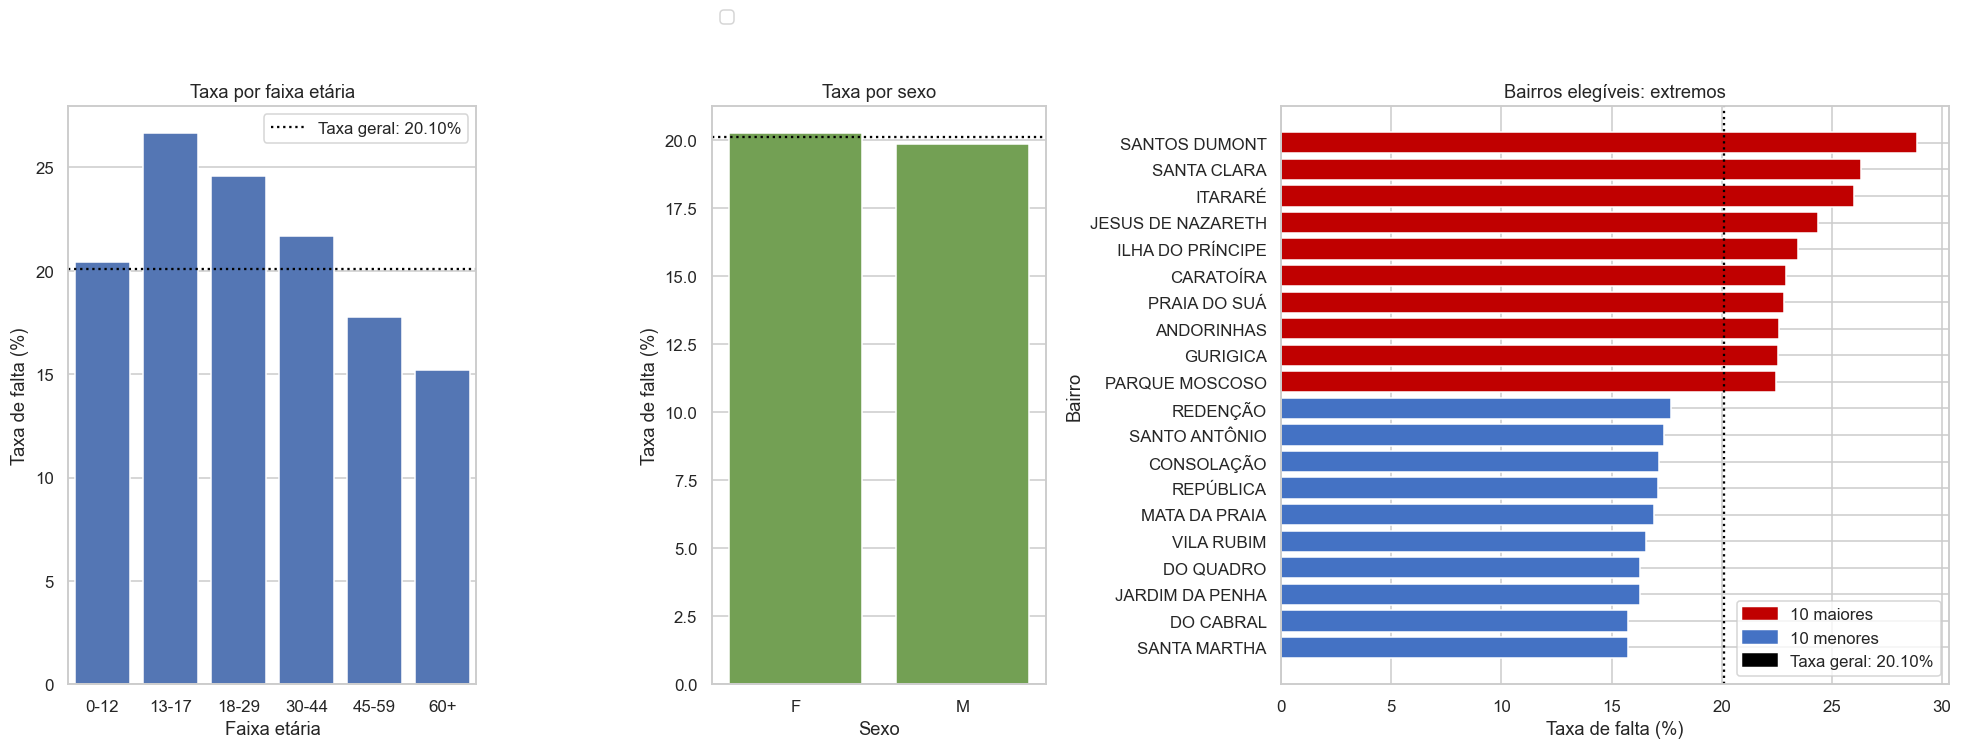

In [4]:
age_bins = [-1, 12, 17, 29, 44, 59, np.inf]
age_labels = ["0-12", "13-17", "18-29", "30-44", "45-59", "60+"]
df["faixa_etaria"] = pd.cut(df["age"], bins=age_bins, labels=age_labels)
age_table = rate_table(df, "faixa_etaria", "P1", age_labels)
sex_table = rate_table(df, "gender", "P1", ["F", "M"])
nb_all = rate_table(df, "neighbourhood", "P1")
all_tables.pop()
nb_eligible = nb_all[nb_all["n"] >= 500].copy()
nb_excluded = int((nb_all["n"] < 500).sum())
nb_selected = pd.concat([nb_eligible.sort_values("taxa_falta_%", ascending=False).head(10), nb_eligible.sort_values("taxa_falta_%").head(10)])
nb_selected = nb_selected.drop_duplicates(subset=["neighbourhood"]).sort_values("taxa_falta_%", ascending=False)
nb_selected.insert(1, "recorte_bairro", np.where(nb_selected["taxa_falta_%"] >= nb_selected["taxa_falta_%"].median(), "10 maiores", "10 menores"))
all_tables.append(nb_selected.assign(pergunta="P1").copy())
print(f"Taxa geral de faltas: {100*GENERAL_RATE:.6f}% (n={len(df)})")
print(f"Bairros fora por n < 500: {nb_excluded}")
show_table(age_table); show_table(sex_table); show_table(nb_selected)

age_plot = age_table.copy()
sex_plot = sex_table.copy()
neighbourhood_plot = nb_selected.copy().sort_values("taxa_falta_%")
fig, axes = plt.subplots(1, 3, figsize=(18, 7), gridspec_kw={"width_ratios": [1.1, 0.9, 1.8]})

sns.barplot(data=age_plot, x="faixa_etaria", y="taxa_falta_%", ax=axes[0], color="#4472c4")
axes[0].set_title("Taxa por faixa etária")
axes[0].set_xlabel("Faixa etária")
axes[0].set_ylabel("Taxa de falta (%)")
add_general_line(axes[0])

sns.barplot(data=sex_plot, x="gender", y="taxa_falta_%", ax=axes[1], color="#70ad47")
axes[1].set_title("Taxa por sexo")
axes[1].set_xlabel("Sexo")
axes[1].set_ylabel("Taxa de falta (%)")
axes[1].legend(loc="upper left", bbox_to_anchor=(0, 1.18), frameon=True)
axes[1].axhline(100 * GENERAL_RATE, color="black", linestyle=":", linewidth=1.5)

colours = neighbourhood_plot["recorte_bairro"].map({"10 maiores": "#c00000", "10 menores": "#4472c4"})
axes[2].barh(neighbourhood_plot["neighbourhood"], neighbourhood_plot["taxa_falta_%"], color=colours)
axes[2].set_title("Bairros elegíveis: extremos")
axes[2].set_xlabel("Taxa de falta (%)")
axes[2].set_ylabel("Bairro")
axes[2].axvline(100 * GENERAL_RATE, color="black", linestyle=":", linewidth=1.5)
from matplotlib.patches import Patch
axes[2].legend(handles=[Patch(color="#c00000", label="10 maiores"), Patch(color="#4472c4", label="10 menores"), Patch(color="black", label=f"Taxa geral: {100*GENERAL_RATE:.2f}%")], loc="lower right")
savefig("p1_perfil.png")

## P2 — Bolsa Família e condições de saúde

`Handcap` é tratado como contagem: 0, 1 e 2+.

Bolsa Família: diferença Sim - Não = 3.962335 pontos percentuais
Hipertensão: diferença Sim - Não = -3.616885 pontos percentuais
Diabetes: diferença Sim - Não = -2.257246 pontos percentuais
Alcoolismo: diferença Sim - Não = -0.155608 pontos percentuais
Deficiências: categorias 0, 1 e 2+; diferença 2+ - 0 calculada na tabela acima.


,pergunta,condicao,categoria,n,faltas,taxa_falta_%
0,P2,Bolsa Família,Não,99089,19534,19.71
1,P2,Bolsa Família,Sim,10800,2557,23.68


,pergunta,condicao,categoria,n,faltas,taxa_falta_%
0,P2,Hipertensão,Não,88214,18363,20.82
1,P2,Hipertensão,Sim,21675,3728,17.20


,pergunta,condicao,categoria,n,faltas,taxa_falta_%
0,P2,Diabetes,Não,101998,20670,20.27
1,P2,Diabetes,Sim,7891,1421,18.01


,pergunta,condicao,categoria,n,faltas,taxa_falta_%
0,P2,Alcoolismo,Não,106546,21424,20.11
1,P2,Alcoolismo,Sim,3343,667,19.95


,pergunta,categoria,n,faltas,taxa_falta_%,condicao
0,P2,0,107672,21694,20.15,Deficiências
1,P2,1,2021,356,17.62,Deficiências
2,P2,2+,196,41,20.92,Deficiências


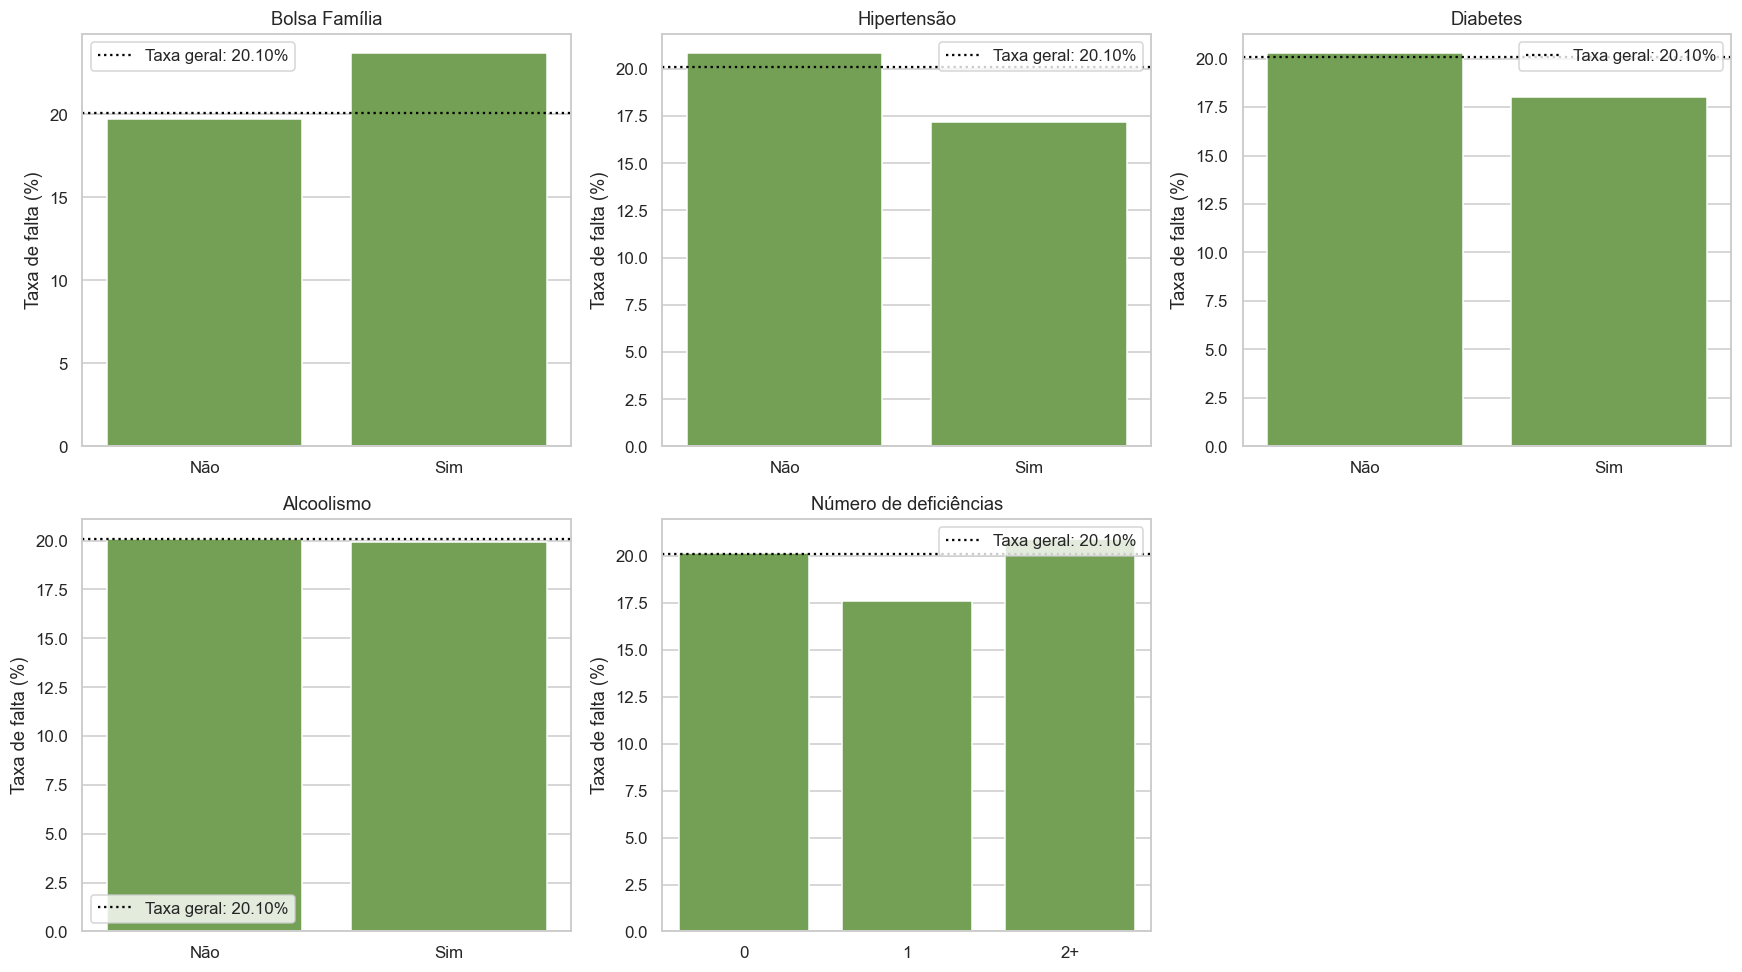

In [5]:
conditions = [("bolsa_familia", "Bolsa Família", {0:"Não", 1:"Sim"}), ("hypertension", "Hipertensão", {0:"Não", 1:"Sim"}), ("diabetes", "Diabetes", {0:"Não", 1:"Sim"}), ("alcoholism", "Alcoolismo", {0:"Não", 1:"Sim"})]
fig, axes = plt.subplots(2, 3, figsize=(16, 9)); axes = axes.ravel()
condition_tables = []
for i, (col, title, labels) in enumerate(conditions):
    temp = df.assign(categoria=df[col].map(labels))
    tab = rate_table(temp, "categoria", "P2", [labels[0], labels[1]])
    tab.insert(1, "condicao", title); all_tables[-1]["condicao"] = title; condition_tables.append(tab)
    diff = tab.loc[tab["categoria"] == labels[1], "taxa_falta_%"].iloc[0] - tab.loc[tab["categoria"] == labels[0], "taxa_falta_%"].iloc[0]
    print(f"{title}: diferença Sim - Não = {diff:.6f} pontos percentuais")
    sns.barplot(data=tab, x="categoria", y="taxa_falta_%", ax=axes[i], color="#70ad47")
    axes[i].set_title(title); axes[i].set_xlabel(""); axes[i].set_ylabel("Taxa de falta (%)"); add_general_line(axes[i])
temp = df.assign(categoria=np.where(df["handicap"] == 0, "0", np.where(df["handicap"] == 1, "1", "2+")))
handicap_table = rate_table(temp, "categoria", "P2", ["0", "1", "2+"])
condition_tables.append(handicap_table.assign(condicao="Deficiências"))
print("Deficiências: categorias 0, 1 e 2+; diferença 2+ - 0 calculada na tabela acima.")
sns.barplot(data=handicap_table, x="categoria", y="taxa_falta_%", ax=axes[4], color="#70ad47")
axes[4].set_title("Número de deficiências"); axes[4].set_xlabel(""); axes[4].set_ylabel("Taxa de falta (%)"); add_general_line(axes[4])
axes[5].axis("off")
for tab in condition_tables: show_table(tab)
savefig("p2_condicoes.png")

## P3 — Tempo de espera

As faixas são 0, 1–2, 3–7, 8–14, 15–30 e 31+ dias.

,pergunta,faixa_espera,n,faltas,taxa_falta_%
0,P3,0,38492,1782,4.63
1,P3,1-2,11859,2694,22.72
3,P3,3-7,20118,5016,24.93
5,P3,8-14,11920,3629,30.44
2,P3,15-30,17220,5589,32.46
4,P3,31+,10280,3381,32.89


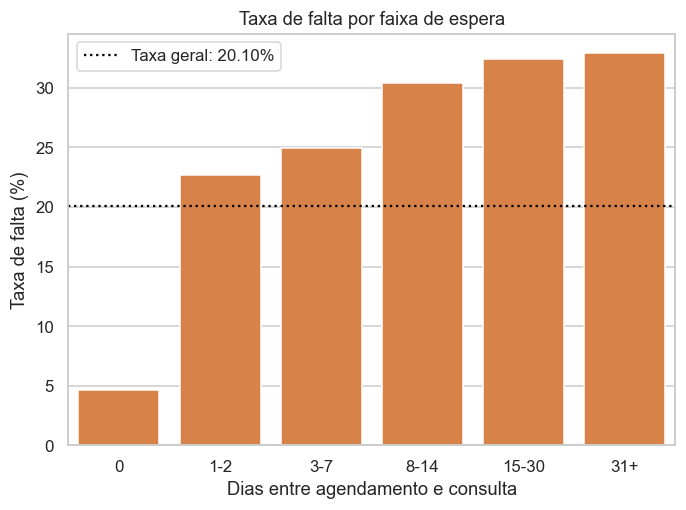

In [6]:
wait_labels = ["0", "1-2", "3-7", "8-14", "15-30", "31+"]
def wait_band(x):
    if x == 0: return "0"
    if x <= 2: return "1-2"
    if x <= 7: return "3-7"
    if x <= 14: return "8-14"
    if x <= 30: return "15-30"
    return "31+"
df["faixa_espera"] = df["waiting_days"].map(wait_band)
p3 = rate_table(df, "faixa_espera", "P3", wait_labels)
show_table(p3)
ax = sns.barplot(data=p3, x="faixa_espera", y="taxa_falta_%", color="#ed7d31")
ax.set_title("Taxa de falta por faixa de espera"); ax.set_xlabel("Dias entre agendamento e consulta"); ax.set_ylabel("Taxa de falta (%)"); add_general_line(ax); savefig("p3_espera.png")

## P4 — Dia da semana da consulta

n de sábado: 39


,pergunta,dia_semana,n,faltas,taxa_falta_%
0,P4,segunda,22570,4632,20.52
1,P4,terça,25506,5098,19.99
2,P4,quarta,25738,5051,19.62
3,P4,quinta,17172,3311,19.28
4,P4,sexta,18864,3990,21.15
5,P4,sábado,39,9,23.08


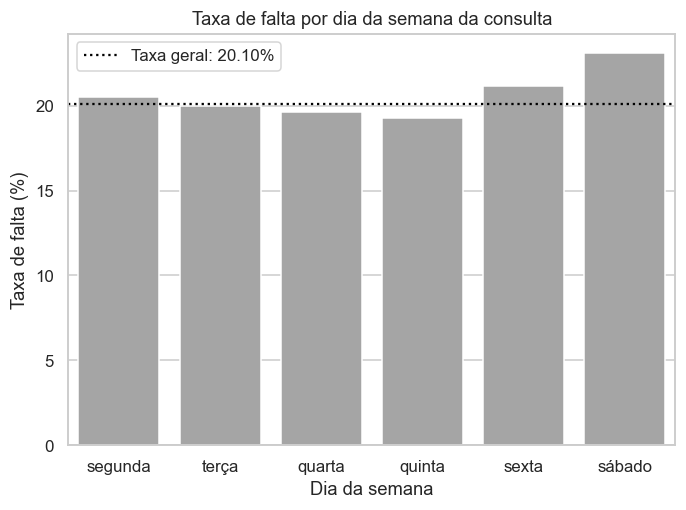

In [7]:
weekday_labels = ["segunda", "terça", "quarta", "quinta", "sexta", "sábado"]
df["dia_semana"] = pd.Categorical(df["appointment_day"].dt.dayofweek.map(dict(enumerate(weekday_labels))), categories=weekday_labels, ordered=True)
p4 = rate_table(df, "dia_semana", "P4", weekday_labels)
print(f"n de sábado: {int(p4.loc[p4['dia_semana'] == 'sábado', 'n'].iloc[0])}")
show_table(p4)
ax = sns.barplot(data=p4, x="dia_semana", y="taxa_falta_%", color="#a5a5a5")
ax.set_title("Taxa de falta por dia da semana da consulta"); ax.set_xlabel("Dia da semana"); ax.set_ylabel("Taxa de falta (%)"); add_general_line(ax); savefig("p4_dia_semana.png")

## P5 — Histórico anterior do mesmo paciente

A comparação é feita por data normalizada: são consideradas anteriores somente consultas cujo `appointment_day` é estritamente anterior ao `scheduled_day` da linha atual. Consultas do mesmo dia não entram no histórico, assim como consultas futuras. Esse filtro evita vazamento do alvo e de eventos posteriores.

,pergunta,grupo_historico,n,faltas,taxa_falta_%
2,P5,sem histórico,79155,17169,21.69
1,P5,nunca faltou antes,20881,2810,13.46
0,P5,já faltou antes,9853,2112,21.44


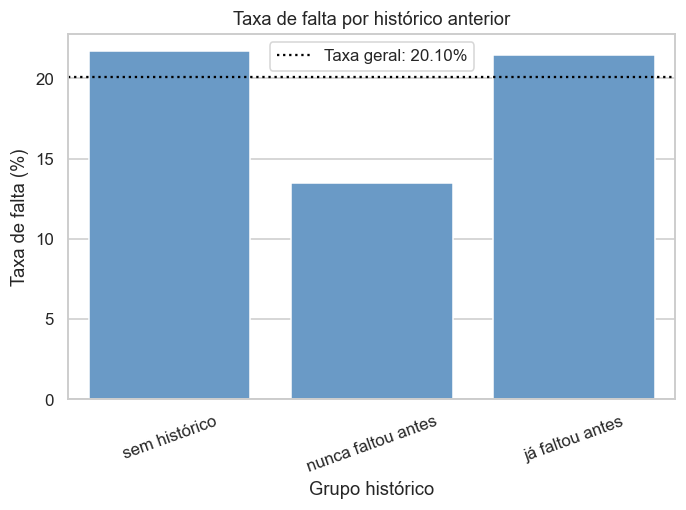

In [8]:
history = add_patient_history(df)
history["grupo_historico"] = np.select(
    [
        history["previous_no_shows"] >= 1,
        (history["previous_appointments"] >= 1) & (history["previous_no_shows"] == 0),
    ],
    ["já faltou antes", "nunca faltou antes"],
    default="sem histórico",
)
p5 = rate_table(history, "grupo_historico", "P5", ["sem histórico", "nunca faltou antes", "já faltou antes"])
show_table(p5)
ax = sns.barplot(data=p5, x="grupo_historico", y="taxa_falta_%", color="#5b9bd5")
ax.set_title("Taxa de falta por histórico anterior"); ax.set_xlabel("Grupo histórico"); ax.set_ylabel("Taxa de falta (%)"); ax.tick_params(axis="x", rotation=20); add_general_line(ax); savefig("p5_historico.png")

## P6 — SMS controlando a espera

A comparação é feita dentro de cada faixa de espera. A tabela mostra também o `n` de cada célula e as faixas em que nenhum agendamento recebeu SMS.

Faixas sem nenhum SMS: ['0', '1-2']


,pergunta,faixa_espera,sms_label,n,faltas,taxa_falta_%
0,P6,0,Sem SMS,38492,1782,4.63
1,P6,1-2,Sem SMS,11859,2694,22.72
5,P6,3-7,Sem SMS,8570,2272,26.51
4,P6,3-7,Com SMS,11548,2744,23.76
9,P6,8-14,Sem SMS,4916,1660,33.77
8,P6,8-14,Com SMS,7004,1969,28.11
3,P6,15-30,Sem SMS,6700,2454,36.63
2,P6,15-30,Com SMS,10520,3135,29.80
7,P6,31+,Sem SMS,3870,1445,37.34
6,P6,31+,Com SMS,6410,1936,30.20


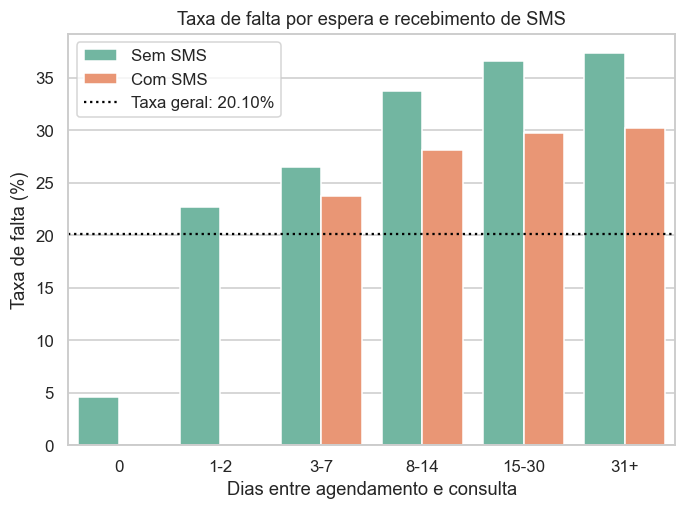

In [9]:
sms_temp = df.assign(sms_label=df["sms_received"].map({0:"Sem SMS", 1:"Com SMS"}))
p6 = rate_table(sms_temp, "faixa_espera", "P6", wait_labels)
all_tables.pop()
# Recalcula a tabela em duas dimensões, mantendo n e taxa por célula.
p6 = sms_temp.groupby(["faixa_espera", "sms_label"], observed=False)["no_show"].agg(n="size", faltas="sum").reset_index()
p6["taxa_falta_%"] = 100 * p6["faltas"] / p6["n"]
p6.insert(0, "pergunta", "P6")
p6["faixa_espera"] = pd.Categorical(p6["faixa_espera"], categories=wait_labels, ordered=True)
p6["sms_label"] = pd.Categorical(p6["sms_label"], categories=["Sem SMS", "Com SMS"], ordered=True)
p6 = p6.sort_values(["faixa_espera", "sms_label"])
all_tables.append(p6.copy())
no_sms_bands = [band for band in wait_labels if int(((sms_temp["faixa_espera"] == band) & (sms_temp["sms_received"] == 1)).sum()) == 0]
print("Faixas sem nenhum SMS:", no_sms_bands)
show_table(p6)
ax = sns.barplot(data=p6, x="faixa_espera", y="taxa_falta_%", hue="sms_label", palette="Set2")
ax.set_title("Taxa de falta por espera e recebimento de SMS"); ax.set_xlabel("Dias entre agendamento e consulta"); ax.set_ylabel("Taxa de falta (%)"); add_general_line(ax); savefig("p6_sms_espera.png")

In [10]:
# Salva uma tabela única com as tabelas completas produzidas pelas perguntas.
combined = pd.concat(all_tables, ignore_index=True, sort=False)
combined.to_csv(TABLE_PATH, index=False)
print("Tabelas salvas em: reports/tabelas_perguntas_negocio.csv")
print("Arquivos de gráficos:")
for path in sorted(FIG_DIR.glob("p[1-6]_*.png")):
    print(path.relative_to(ROOT))

Tabelas salvas em: reports/tabelas_perguntas_negocio.csv
Arquivos de gráficos:
reports\figures\p1_perfil.png
reports\figures\p2_condicoes.png
reports\figures\p3_espera.png
reports\figures\p4_dia_semana.png
reports\figures\p5_historico.png
reports\figures\p6_sms_espera.png


## Comparação com o dicionário de dados

A comparação abaixo usa o CSV bruto para reproduzir os cinco números solicitados e, depois, o conjunto após a pipeline de limpeza/deduplicação.

In [11]:
def comparison(data, label):
    typed = build_features(data.copy())
    return pd.Series({
        "conjunto": label,
        "total_linhas": len(typed),
        "pacientes_distintos": typed["patient_id"].nunique(),
        "taxa_geral_%": 100 * typed["no_show"].mean(),
        "taxa_mesmo_dia_%": 100 * typed.loc[typed["same_day"] == 1, "no_show"].mean(),
        "taxa_com_sms_%": 100 * typed.loc[typed["sms_received"] == 1, "no_show"].mean()
    })
comparison_table = pd.DataFrame([comparison(raw, "bruto"), comparison(df, "após limpeza")])
display(comparison_table.style.format({c: "{:.6f}" for c in comparison_table.columns if c.endswith("_%")}))

,conjunto,total_linhas,pacientes_distintos,taxa_geral_%,taxa_mesmo_dia_%,taxa_com_sms_%
0,bruto,110527,62299,20.193256,4.646941,27.574545
1,após limpeza,109889,62298,20.103013,4.629533,27.574545
